# 15. Two-dimensional flow: a pseudo-spectral Navier–Stokes solver

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/15_two_dimensional_flow.ipynb)

*Goes beyond L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000), using the tools built in notebooks 1 to 14.*

Much of what is known about turbulence comes from one kind of program: a Fourier
pseudo-spectral solver for the Navier–Stokes equations in a periodic box. Its ingredients have
all appeared in this course: FFT differentiation (notebook 2), aliasing (notebooks 2 and 3) and
an integrating factor with Runge–Kutta time stepping (notebook 11). This notebook assembles
them into a two-dimensional solver of about forty lines and tests it thoroughly before using it.

- the vorticity–stream function form of the equations, and why it suits Fourier methods
- derivatives in Fourier space, products in physical space
- aliasing of the nonlinear term and the 2/3 rule
- verification by an exact solution, a convergence order and two conservation laws

**Worked examples:** the roll-up and pairing of a double shear layer, and decaying
two-dimensional turbulence.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from types import SimpleNamespace
from scipy.fft import fft, fft2, rfft2, irfft2
from matplotlib.animation import FuncAnimation, PillowWriter

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 15.1 The equations

**Problem.** Compute the incompressible flow of a fluid of kinematic viscosity $\nu$ on the
periodic square $[0, 2\pi)^2$, from a given initial velocity field.

**By hand.** The velocity $(u, v)$ obeys the Navier–Stokes equations with the constraint
$u_x + v_y = 0$. In two dimensions both the constraint and the pressure can be removed.

- Take the curl of the momentum equation. The pressure gradient disappears, and what remains is
  a transport equation for the **vorticity** $\omega = v_x - u_y$:
  $$\omega_t + u\,\omega_x + v\,\omega_y = \nu\,\nabla^2\omega .$$
  Vorticity is carried with the flow and diffuses, like a dye, except that it also determines
  the flow.
- Write the velocity in terms of a **stream function**, $u = \psi_y$, $v = -\psi_x$. Then
  $u_x + v_y = \psi_{yx} - \psi_{xy} = 0$ for any $\psi$: incompressibility is automatic. The
  definition of the vorticity becomes a Poisson equation, $\nabla^2\psi = -\omega$.

One scalar unknown, $\omega$, replaces two velocities and a pressure. And on a periodic domain
the Poisson equation costs almost nothing. For a Fourier mode $e^{i(k_x x + k_y y)}$ the
Laplacian is multiplication by $-(k_x^2 + k_y^2) = -k^2$, so

$$\hat\psi = \frac{\hat\omega}{k^2},\qquad \hat u = i k_y\,\hat\psi,\qquad \hat v = -i k_x\,\hat\psi .$$

The mode $k = 0$ needs a remark. The mean vorticity of a periodic flow is zero (it is the
circulation around the boundary of the box, where opposite sides cancel), and the mean of
$\psi$ is an arbitrary constant, set to zero.

## 15.2 Derivatives in Fourier space, products in physical space

The viscous term is linear and diagonal in Fourier space. The advection term
$u\,\omega_x + v\,\omega_y$ is a product, which in Fourier space would be a convolution costing
$O(N^4)$ operations. The **pseudo-spectral** idea is to do each operation where it is cheap:

1. from $\hat\omega$ compute $\hat u$, $\hat v$, $\widehat{\omega_x}$, $\widehat{\omega_y}$
   (multiplications in Fourier space);
2. transform the four fields to the grid, and multiply them point by point;
3. transform the product back.

Five two-dimensional FFTs per evaluation, $O(N^2\log N)$ operations.

Because the fields are real, `rfft2` stores only half of the coefficients, $k_y \ge 0$. Arrays
are indexed `[i, j]` for the point $(x_i, y_j)$, so `kx` varies along the first axis and `ky`
along the second. As in notebook 2, the Nyquist mode is set to zero in first derivatives.

In [2]:
def make_grid(N, dealias=True):
    """Grid, wavenumbers and Fourier-space operators for the periodic square with N x N points (N even)."""
    x = 2 * np.pi * np.arange(N) / N
    X, Y = np.meshgrid(x, x, indexing="ij")
    kx = np.fft.fftfreq(N, 1 / N)[:, None]                  # 0, 1, ..., N/2-1, -N/2, ..., -1
    ky = np.fft.rfftfreq(N, 1 / N)[None, :]                 # 0, 1, ..., N/2
    k2 = kx**2 + ky**2
    inv_k2 = np.zeros_like(k2)
    inv_k2[k2 > 0] = 1 / k2[k2 > 0]                         # the mean of ψ is set to zero
    ddx = 1j * kx * (np.abs(kx) < N / 2)                    # first derivatives, Nyquist mode zeroed
    ddy = 1j * ky * (ky < N / 2)
    keep = (np.abs(kx) < N / 3) & (ky < N / 3)              # the 2/3 rule of section 15.3
    mask = keep.astype(float) if dealias else np.ones_like(k2)
    return SimpleNamespace(N=N, X=X, Y=Y, kx=kx, ky=ky, k2=k2, inv_k2=inv_k2, ddx=ddx, ddy=ddy, mask=mask)

def velocity(omega_hat, g, mean_flow=(0.0, 0.0)):
    """Velocity components on the grid from the Fourier coefficients of the vorticity."""
    psi_hat = omega_hat * g.inv_k2
    return mean_flow[0] + irfft2(g.ddy * psi_hat), mean_flow[1] - irfft2(g.ddx * psi_hat)

def rhs(omega_hat, g, mean_flow=(0.0, 0.0)):
    """Fourier coefficients of the advection term −(u ω_x + v ω_y)."""
    u, v = velocity(omega_hat, g, mean_flow)
    return -g.mask * rfft2(u * irfft2(g.ddx * omega_hat) + v * irfft2(g.ddy * omega_hat))

**Verify** the building blocks on a field with known answers. For
$\omega = 2\cos x\cos y$ the stream function is $\psi = \cos x\cos y$, so
$u = -\cos x\sin y$ and $v = \sin x\cos y$. This array of counter-rotating cells is the
**Taylor–Green vortex**. Its advection term vanishes identically, because $\omega = 2\psi$ and
the velocity runs along the lines of constant $\psi$.

That field contains only the wavenumbers $(\pm1, \pm1)$, so it cannot tell whether the division
by $k^2$ is right anywhere else. A second field with other wavenumbers closes the gap: for
$\omega = \cos(2x + y) + \sin(x - 3y)$ the stream function is
$\psi = \tfrac15\cos(2x + y) + \tfrac1{10}\sin(x - 3y)$.

In [3]:
g = make_grid(16)
taylor_green = 2 * np.cos(g.X) * np.cos(g.Y)
u, v = velocity(rfft2(taylor_green), g)
assert np.abs(u + np.cos(g.X) * np.sin(g.Y)).max() < 1e-12 and np.abs(v - np.sin(g.X) * np.cos(g.Y)).max() < 1e-12
assert np.abs(irfft2(g.ddx * rfft2(u) + g.ddy * rfft2(v))).max() < 1e-12     # divergence-free
assert np.abs(rhs(rfft2(taylor_green), g)).max() < 1e-12                     # no advection of ω by its own flow

wave_1, wave_2 = 2 * g.X + g.Y, g.X - 3 * g.Y                                # phases of the second test field
u, v = velocity(rfft2(np.cos(wave_1) + np.sin(wave_2)), g)
assert np.abs(u + np.sin(wave_1) / 5 + 3 * np.cos(wave_2) / 10).max() < 1e-12            # u = ψ_y
assert np.abs(v - 2 * np.sin(wave_1) / 5 + np.cos(wave_2) / 10).max() < 1e-12            # v = −ψ_x
print("velocity from vorticity (two test fields), zero divergence, zero advection term: all correct to rounding")

velocity from vorticity (two test fields), zero divergence, zero advection term: all correct to rounding


## 15.3 Aliasing and the 2/3 rule

Step 2 hides a trap. Multiplying two fields that contain wavenumbers up to $K$ creates
wavenumbers up to $2K$. If $2K$ exceeds what the grid can hold, the excess does not vanish.
As notebook 2 showed, on an $N$-point grid the wavenumber $k$ cannot be told apart from
$k \pm N$, so the excess reappears, **aliased**, at a lower wavenumber where it does not belong.

**By hand, in one dimension.** On a grid of $N = 12$ points take $u = \cos 4x$. Its square is
$u^2 = \tfrac12 + \tfrac12\cos 8x$. But $8 = 12 - 4$, and on this grid $\cos 8x$ and $\cos 4x$
take the same values. The grid therefore reports $u^2 = \tfrac12 + \tfrac12\cos 4x$:
energy that should have left towards small scales is fed back into the mode that produced it.

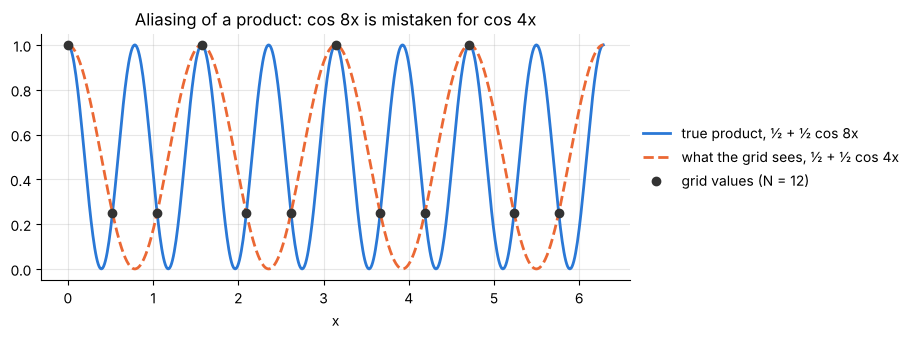

In [4]:
N = 12
x = 2 * np.pi * np.arange(N) / N
fine = np.linspace(0, 2 * np.pi, 600)
coefficients = fft(np.cos(4 * x) ** 2) / N
assert np.isclose(abs(coefficients[4]), 0.25) and np.isclose(abs(coefficients[0]), 0.5)     # a false mode 4, amplitude 2 x 0.25

fig, ax = plt.subplots(figsize=(7.6, 3.2))
ax.plot(fine, np.cos(4 * fine) ** 2, label="true product, ½ + ½ cos 8x")
ax.plot(fine, 0.5 + 0.5 * np.cos(4 * fine), "--", label="what the grid sees, ½ + ½ cos 4x")
ax.plot(x, np.cos(4 * x) ** 2, "o", color="0.2", label="grid values (N = 12)")
ax.set(xlabel="x", title="Aliasing of a product: cos 8x is mistaken for cos 4x")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

**The 2/3 rule.** Keep only the modes with $|k| < K$ and set the others to zero, before and
after every product. The product then reaches $2K$, and its aliases land at $N - 2K$ and above.
They miss the retained band if $N - 2K \ge K$, that is if $K \le N/3$. So with **two thirds**
of the modes in each direction kept, the retained coefficients of a quadratic product are exact,
with no aliasing error at all. The price is resolution, as
$N$ points per direction carry only $2N/3$ useful modes. The `mask` built in `make_grid` does
this, and it is applied to the product in `rhs`.

**Verify** in one dimension: for band-limited $u$ and $v$ the masked coefficients of the
product, computed on the coarse grid, agree with those computed on a grid fine enough to have
no aliasing at all.

In [5]:
rng = np.random.default_rng(0)
N, N_fine = 12, 48
k = np.fft.fftfreq(N, 1 / N)
keep = np.abs(k) < N / 3                                              # |k| <= 3
u_hat, v_hat = (keep * fft(rng.standard_normal(N)) for _ in range(2))

def on_grid(c_hat, M):
    """Values on an M-point grid of the trigonometric polynomial with the N coefficients c_hat."""
    points = 2 * np.pi * np.arange(M) / M
    return np.real(np.exp(1j * np.outer(points, k)) @ c_hat) / N

coarse = fft(on_grid(u_hat, N) * on_grid(v_hat, N)) / N
exact = (fft(on_grid(u_hat, N_fine) * on_grid(v_hat, N_fine)) / N_fine)[k.astype(int)]    # the same wavenumbers, no aliasing
print(f"error of the retained coefficients: {np.abs(coarse - exact)[keep].max():.1e}"
      f"      error of the discarded ones: {np.abs(coarse - exact)[~keep].max():.2f}")
assert np.abs(coarse - exact)[keep].max() < 1e-13 and np.abs(coarse - exact)[~keep].max() > 0.01

error of the retained coefficients: 8.5e-17      error of the discarded ones: 0.03


The retained coefficients are exact to rounding. The discarded ones are where the aliases
went. Section 15.6 shows what this buys in a flow computation.

## 15.4 Time stepping

In Fourier space the vorticity equation is a set of ordinary differential equations,

$$\frac{d\hat\omega}{dt} = -\nu k^2\,\hat\omega + \hat{\mathcal N}(\hat\omega),$$

where $\hat{\mathcal N}$ is the advection term computed by `rhs`. The viscous term is stiff
(its rates reach $\nu N^2/2$) but linear and diagonal, so it can be integrated exactly with the
**integrating factor** of notebook 11. Substituting $\hat\omega = e^{-\nu k^2 t}\,\hat w$ gives

$$\frac{d\hat w}{dt} = e^{\nu k^2 t}\,\hat{\mathcal N}\big(e^{-\nu k^2 t}\,\hat w\big),$$

an equation without the stiff term, which the classical fourth-order Runge–Kutta formula
advances. Written out in terms of $\hat\omega$, with $E = e^{-\nu k^2\Delta t/2}$, each stage
is multiplied by the decay factor for the time between that stage and the end of the step.
The time step is then limited only by advection. A safe estimate from the stability region of
RK4 (notebook 9) is $\Delta t < 2.8/\big(k_{\max}\,(|u| + |v|)_{\max}\big)$, with
$k_{\max} = N/3$ after dealiasing. The function `step_limit` below evaluates it for a given
field, and both showcases check their time step against it.

In [6]:
def simulate(omega0, g, nu, dt, n_steps, save_every=None, mean_flow=(0.0, 0.0)):
    """Advance the vorticity field omega0 by n_steps steps of size dt.

    Returns the final vorticity, or the array of fields saved every save_every steps (including the first).
    """
    E = np.exp(-nu * g.k2 * dt / 2)                         # viscous decay over half a step
    E2 = E * E
    w = g.mask * rfft2(omega0)
    saved = [irfft2(w)]
    for n in range(1, n_steps + 1):
        a = rhs(w, g, mean_flow)                            # the four Runge-Kutta stages
        b = rhs(E * (w + dt / 2 * a), g, mean_flow)
        c = rhs(E * w + dt / 2 * b, g, mean_flow)
        d = rhs(E2 * w + dt * E * c, g, mean_flow)
        w = E2 * w + dt / 6 * (E2 * a + 2 * E * (b + c) + d)
        if save_every and n % save_every == 0:
            saved.append(irfft2(w))
    return np.array(saved) if save_every else irfft2(w)

def energy_enstrophy(omega, g):
    """Kinetic energy ½<u² + v²> and enstrophy ½<ω²>, averaged over the box."""
    u, v = velocity(rfft2(omega), g)
    return 0.5 * np.mean(u**2 + v**2), 0.5 * np.mean(omega**2)

def step_limit(omega, g):
    """The estimate 2.8 / (k_max (|u| + |v|)_max) of the largest stable time step for the field omega."""
    u, v = velocity(rfft2(omega), g)
    return 2.8 / (g.N / 3 * (np.abs(u) + np.abs(v)).max())

That is the whole solver: `make_grid`, `velocity`, `rhs` and `simulate`.

## 15.5 Verification

**An exact solution.** For the Taylor–Green vortex the advection term vanishes and each cell
decays by viscosity alone: $\omega = 2\cos x\cos y\;e^{-2\nu t}$ solves the full equations.

This is a weaker test than it looks, because the nonlinear term only has to return zero. A
stronger one follows from Galilean invariance: seen from a frame moving at $(-U, -V)$, the same
vortex is swept across the grid,
$\omega = 2\cos(x - Ut)\cos(y - Vt)\,e^{-2\nu t}$, and now the solver must carry the vortex
across the grid at the right speed. The optional argument `mean_flow` adds the uniform
velocity $(U, V)$ for this test. The advection of the vortex by its own velocity still
vanishes, so the fully nonlinear path needs tests of its own: the order in time below and the
conservation laws of 15.6.

In [7]:
g = make_grid(32)
nu, T, dt = 0.05, 2.0, 0.005
omega0 = 2 * np.cos(g.X) * np.cos(g.Y)

still = simulate(omega0, g, nu, dt, round(T / dt))
error_still = np.abs(still - omega0 * np.exp(-2 * nu * T)).max()

U, V = 1.0, 0.5
swept = simulate(omega0, g, nu, dt, round(T / dt), mean_flow=(U, V))
error_swept = np.abs(swept - 2 * np.cos(g.X - U * T) * np.cos(g.Y - V * T) * np.exp(-2 * nu * T)).max()

print(f"Taylor-Green vortex at t = {T}: error {error_still:.1e} at rest, {error_swept:.1e} swept by a uniform flow")
assert error_still < 1e-12 and error_swept < 5e-10

Taylor-Green vortex at t = 2.0: error 1.3e-14 at rest, 6.5e-11 swept by a uniform flow


The vortex at rest is reproduced to rounding error, since the integrating factor is exact. The
swept vortex shows the small time-stepping error of RK4, about $10^{-10}$.

**The order in time.** For a flow in which the nonlinear term is fully active, compare runs
with decreasing time steps against a reference with a much smaller one. Halving $\Delta t$
should divide the error by $2^4 = 16$.

In [8]:
def three_waves(g):
    return np.sin(g.X) * np.sin(g.Y) + np.cos(2 * g.X + g.Y) + 0.5 * np.sin(g.X - 3 * g.Y)

omega0 = three_waves(g)
reference = simulate(omega0, g, 0.01, 1 / 640, 640)
steps = np.array([10, 20, 40, 80])
errors = np.array([np.abs(simulate(omega0, g, 0.01, 1 / n, n) - reference).max() for n in steps])
orders = np.log2(errors[:-1] / errors[1:])
for n, e in zip(steps, errors):
    print(f"dt = 1/{n:<3d}  error at t = 1: {e:.2e}")
print("observed orders:", np.round(orders, 2))
assert np.all(np.abs(orders - 4) < 0.3)

dt = 1/10   error at t = 1: 3.91e-05
dt = 1/20   error at t = 1: 2.30e-06
dt = 1/40   error at t = 1: 1.37e-07
dt = 1/80   error at t = 1: 8.33e-09
observed orders: [4.09 4.07 4.04]


## 15.6 Conservation laws: what dealiasing buys

Without viscosity a two-dimensional flow conserves two quadratic quantities: the kinetic
**energy** $E = \tfrac12\langle u^2 + v^2\rangle$ and the **enstrophy**
$Z = \tfrac12\langle\omega^2\rangle$ (angle brackets are averages over the box). The second
holds because each fluid particle keeps its vorticity. A dealiased Fourier method inherits
both laws exactly, apart from the time-stepping error. An aliased one does not.

**Problem.** Run the three-wave flow of 15.5 with $\nu = 0$ on a deliberately coarse grid,
$N = 32$, up to $t = 6$, with and without the 2/3 rule, and monitor $E$ and $Z$. The flow
stretches the vorticity into ever thinner filaments, so by the end the grid is too coarse for
it in both runs.

with the 2/3 rule  : relative change at t = 6:  energy 8.6e-14   enstrophy 7.8e-12


without dealiasing : relative change at t = 6:  energy 4.5e-02   enstrophy 2.1e+00


at t = 1, drift of the enstrophy without dealiasing: 7e-08
at t = 1, largest error of the vorticity:  with the 2/3 rule 1.1e-02   without dealiasing 1.1e-03


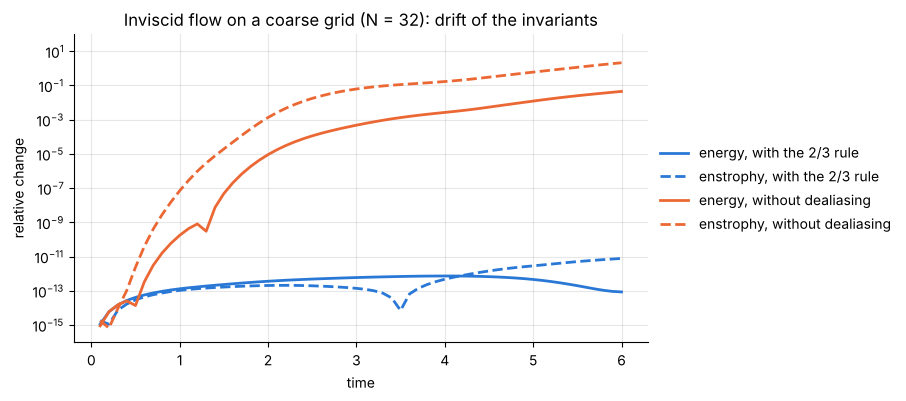

In [9]:
dt, n_steps, every = 0.005, 1200, 20
time = dt * every * np.arange(n_steps // every + 1)
drift, at_time_1 = {}, {}
for label, dealias in (("with the 2/3 rule", True), ("without dealiasing", False)):
    grid = make_grid(32, dealias=dealias)
    fields = simulate(three_waves(grid), grid, 0.0, dt, n_steps, save_every=every)
    at_time_1[label] = fields[10]                                        # the vorticity at t = 1, used below
    history = np.array([energy_enstrophy(field, grid) for field in fields])
    drift[label] = np.abs(history / history[0] - 1)
    print(f"{label:19s}: relative change at t = 6:  energy {drift[label][-1, 0]:.1e}   enstrophy {drift[label][-1, 1]:.1e}")

assert drift["with the 2/3 rule"].max() < 1e-10
assert drift["without dealiasing"][-1, 1] > 1.0 and drift["without dealiasing"][-1, 0] > 0.01

# conservation is one thing and accuracy another: compare both runs at t = 1 with a resolved one (N = 128)
fine_grid = make_grid(128)
resolved = simulate(three_waves(fine_grid), fine_grid, 0.0, dt, 200)[::4, ::4]          # every 4th point is a point of the coarse grid
error_1 = {label: np.abs(field - resolved).max() for label, field in at_time_1.items()}
print(f"at t = 1, drift of the enstrophy without dealiasing: {drift['without dealiasing'][10, 1]:.0e}")
print(f"at t = 1, largest error of the vorticity:  with the 2/3 rule {error_1['with the 2/3 rule']:.1e}   without dealiasing {error_1['without dealiasing']:.1e}")
assert drift["without dealiasing"][10].max() < 1e-6
assert 5e-3 < error_1["with the 2/3 rule"] < 2e-2 and error_1["without dealiasing"] < 0.2 * error_1["with the 2/3 rule"]

fig, ax = plt.subplots(figsize=(7.4, 4))
for (label, d), colour in zip(drift.items(), ("C0", "C1")):
    ax.semilogy(time[1:], np.maximum(d[1:, 0], 1e-17), color=colour, label=f"energy, {label}")
    ax.semilogy(time[1:], np.maximum(d[1:, 1], 1e-17), "--", color=colour, label=f"enstrophy, {label}")
ax.set(xlabel="time", ylabel="relative change", ylim=(1e-16, 1e2), title="Inviscid flow on a coarse grid (N = 32): drift of the invariants")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

With the 2/3 rule both invariants are held to eleven digits, even after the flow has outgrown
the grid. Without it the enstrophy has tripled by $t = 6$: aliasing feeds the smallest
scales, and a longer run (not included here) overflows soon after $t = 8$.

Two honest remarks. First, dealiasing is not free. At $t = 1$ the aliased run still conserves
both invariants to seven digits, and the last line of the output shows that it is the **more**
accurate of the two: against a resolved run with $N = 128$ its error is $1\times10^{-3}$, and
that of the dealiased run is $1\times10^{-2}$, because the 2/3 rule has thrown away the
modes from 11 to 16, which the aliased run still uses. (A longer reference run, not included
here, shows the aliased run ahead until $t \approx 2.5$.) What dealiasing buys is conservation
and stability once the spectrum reaches the edge of the grid, which in turbulence is always.
Second, conservation is not accuracy: the dealiased run at $t = 6$ is stable and conserves
what it should, but its small scales are wrong, because an inviscid flow keeps producing
scales that no grid can hold. Viscosity, with enough resolution to reach the scale at which
it acts, is what makes a computation converge.

## 15.7 Showcase 1: roll-up of a double shear layer

**Problem.** Two streams slide past each other in opposite directions: fluid in the middle band
of the box moves to the right at speed 1 and the fluid above and below moves to the left. The
velocity changes over two thin layers of thickness $\delta = 0.15$ at $y = \pi/2$ and
$y = 3\pi/2$, so the vorticity is concentrated in two sheets of opposite sign,

$$\omega(x, y, 0) = \frac1\delta\Big[\operatorname{sech}^2\frac{y - 3\pi/2}{\delta} - \operatorname{sech}^2\frac{y - \pi/2}{\delta}\Big]
  + 0.1\cos 2x + 0.02\cos(x + 1),$$

with $\nu = 10^{-3}$. The last two terms are a small disturbance: a wave with two
periods in the box and a weaker one with a single period.

A flat shear layer is unstable: this is the **Kelvin–Helmholtz instability**, which makes
flags flap, raises waves on wind-blown water and governs the mixing layer between two streams
in a combustor or behind a splitter plate. Linear theory says that disturbances with a
wavelength of roughly fourteen layer thicknesses grow fastest.

time step 0.015 against the advective estimate of 15.4: 0.0156 at its smallest during the run


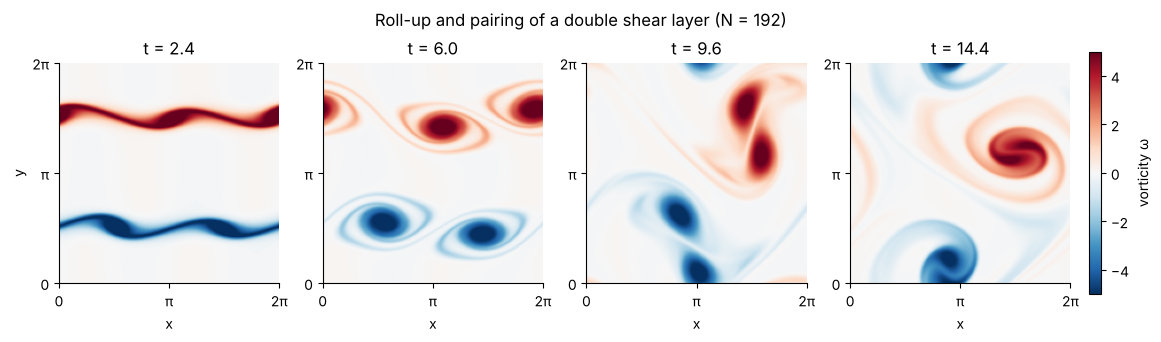

In [10]:
def double_shear_layer(g, delta=0.15):
    wrap = lambda d: (d + np.pi) % (2 * np.pi) - np.pi                    # periodic distance in y
    sheet = lambda y0: 1 / (delta * np.cosh(wrap(g.Y - y0) / delta) ** 2)
    return sheet(3 * np.pi / 2) - sheet(np.pi / 2) + 0.1 * np.cos(2 * g.X) + 0.02 * np.cos(g.X + 1)

nu_layer, dt, every, n_frames = 1e-3, 0.015, 16, 60
g = make_grid(192)
frames = simulate(double_shear_layer(g), g, nu_layer, dt, every * n_frames, save_every=every)
frame_times = dt * every * np.arange(n_frames + 1)
limit = min(step_limit(field, g) for field in frames)
print(f"time step {dt} against the advective estimate of 15.4: {limit:.4f} at its smallest during the run")
assert dt < limit

def show_fields(fields, times, limit, title):
    fig, axes = plt.subplots(1, len(fields), figsize=(11.5, 3.3), constrained_layout=True)
    for ax, field, t in zip(axes, fields, times):
        image = ax.imshow(field.T, origin="lower", extent=(0, 2 * np.pi, 0, 2 * np.pi), cmap="RdBu_r", vmin=-limit, vmax=limit)
        ax.set(title=f"t = {t:.1f}", xticks=[0, np.pi, 2 * np.pi], yticks=[0, np.pi, 2 * np.pi], xlabel="x",
               xticklabels=["0", "π", "2π"], yticklabels=["0", "π", "2π"])
        ax.grid(False)
    axes[0].set_ylabel("y")
    fig.colorbar(image, ax=axes, label="vorticity ω", shrink=0.9, pad=0.01)
    fig.suptitle(title)

chosen = [10, 25, 40, 60]
show_fields(frames[chosen], frame_times[chosen], 5.0, "Roll-up and pairing of a double shear layer (N = 192)")

Each sheet first rolls up into two vortices ("billows"), at the wavelength of the stronger
disturbance. Later the two billows of each layer orbit one another and merge into one, helped
by the weak single-period disturbance. This **vortex pairing** is how a mixing layer thickens
downstream.

**Verify.** There is no exact solution, so the checks are indirect: quantities that must hold
(zero mean vorticity, energy and enstrophy that only decrease), and a repeat of the run on a
coarser grid, which must give the same answer if the flow is resolved.

In [11]:
history = np.array([energy_enstrophy(field, g) for field in frames])
assert np.abs(frames.mean(axis=(1, 2))).max() < 1e-12                       # mean vorticity stays zero
assert np.all(np.diff(history[:, 0]) < 0) and np.all(np.diff(history[:, 1]) < 0)

g_coarse = make_grid(128)
coarse = simulate(double_shear_layer(g_coarse), g_coarse, nu_layer, dt, every * n_frames)
E_coarse, Z_coarse = energy_enstrophy(coarse, g_coarse)
print(f"at t = {frame_times[-1]:.1f}:   N = 192: E = {history[-1, 0]:.6f}, Z = {history[-1, 1]:.5f}"
      f"     N = 128: E = {E_coarse:.6f}, Z = {Z_coarse:.5f}")
assert abs(E_coarse / history[-1, 0] - 1) < 1e-3 and abs(Z_coarse / history[-1, 1] - 1) < 1e-3
difference = np.abs(coarse[::2, ::2] - frames[-1][::3, ::3]).max()          # every 2nd point of one grid is every 3rd of the other
print(f"largest difference between the two vorticity fields at the common grid points: {difference:.3f} (the peak vorticity is {np.abs(frames[-1]).max():.2f})")
assert difference < 0.02 * np.abs(frames[-1]).max()

at t = 14.4:   N = 192: E = 0.424190, Z = 0.76717     N = 128: E = 0.424189, Z = 0.76709
largest difference between the two vorticity fields at the common grid points: 0.065 (the peak vorticity is 5.42)


Energy and enstrophy agree to four digits, and the vorticity itself to about one per cent of
its peak value, at every common grid point, after the layers have rolled up and paired. The
picture is a property of the equations and not of the grid. (A separate run with $N = 256$
and half the time step, too slow to include here, differs from $N = 192$ by less than 0.1 per
cent of the peak. The step has to shrink with the grid: the estimate of 15.4 printed above,
0.0156 for $N = 192$, falls to 0.012 for $N = 256$, and a run on that grid with a step of
0.016 blows up.)

The same data make the animation. The next cell writes `two_dimensional_flow.gif` next to the
notebook. The copy shown below it is the one stored in the repository, so that it also
displays in Google Colab.

In [12]:
fig = plt.figure(figsize=(4, 4), dpi=70)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_axis_off()
image = ax.imshow(frames[0].T, origin="lower", cmap=plt.get_cmap("RdBu_r", 32), vmin=-5, vmax=5)    # 32 colours keep the file small
label = ax.text(0.03, 0.95, "", transform=ax.transAxes, fontsize=11, va="top")

def draw(i):
    image.set_data(frames[i].T)
    label.set_text(f"t = {frame_times[i]:.1f}")
    return image, label

FuncAnimation(fig, draw, frames=len(frames)).save("two_dimensional_flow.gif", writer=PillowWriter(fps=12), dpi=70)
plt.close(fig)

![Vorticity of a double shear layer rolling up into vortices that then pair](https://raw.githubusercontent.com/ktwyw/spectral-methods-in-python/main/notebooks/two_dimensional_flow.gif)

## 15.8 Showcase 2: decaying two-dimensional turbulence

**Problem.** Start from a random vorticity field made of many small eddies and let it evolve
with no forcing. The initial field is Gaussian noise (seed 0) filtered in Fourier space by
$k^2 e^{-(k/8)^2}$, which puts the eddies at wavenumbers around 6 to 9 (the energy spectrum
peaks at 6, the enstrophy spectrum at 9), scaled to a kinetic energy of $\tfrac12$. Take
$\nu = 10^{-3}$ and $N = 160$.

Two-dimensional turbulence is not a model of the turbulence in a pipe, which is
three-dimensional. It describes flows confined to thin layers: soap films, stratified or
rotating tanks, and the large scales of the atmosphere and oceans.

time step 0.0125 against the advective estimate of 15.4: 0.0135 at its smallest during the run


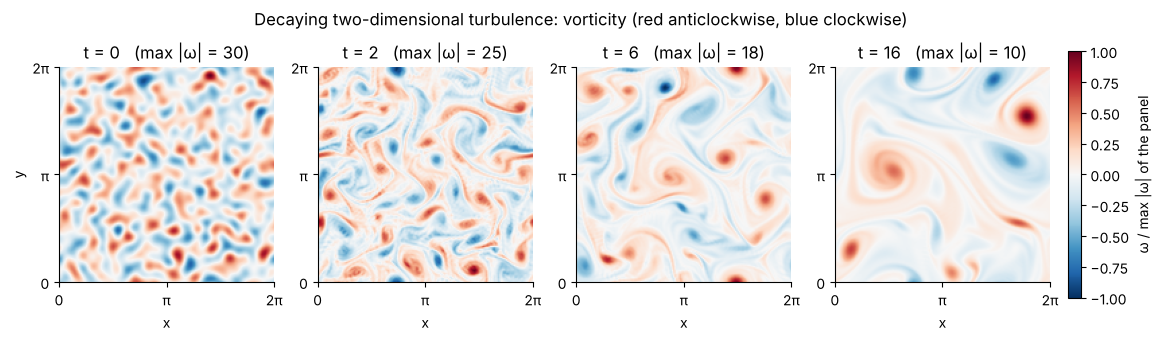

In [13]:
def random_vorticity(g, k_peak=8.0, seed=0):
    rng = np.random.default_rng(seed)
    k = np.sqrt(g.k2)
    omega = irfft2(g.mask * k**2 * np.exp(-(k / k_peak) ** 2) * rfft2(rng.standard_normal((g.N, g.N))))
    return omega / np.sqrt(2 * energy_enstrophy(omega, g)[0])            # kinetic energy ½

nu_turb, dt, every = 1e-3, 0.0125, 16
g = make_grid(160)
fields = simulate(random_vorticity(g), g, nu_turb, dt, 1280, save_every=every)
times = dt * every * np.arange(len(fields))
limit = min(step_limit(field, g) for field in fields)
print(f"time step {dt} against the advective estimate of 15.4: {limit:.4f} at its smallest during the run")
assert dt < limit

fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.3), constrained_layout=True)
for ax, index in zip(axes, [0, 10, 30, 80]):
    peak = np.abs(fields[index]).max()                                    # each panel is scaled by its own peak
    image = ax.imshow(fields[index].T / peak, origin="lower", extent=(0, 2 * np.pi, 0, 2 * np.pi), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set(title=f"t = {times[index]:.0f}   (max |ω| = {peak:.0f})", xticks=[0, np.pi, 2 * np.pi], yticks=[0, np.pi, 2 * np.pi],
           xlabel="x", xticklabels=["0", "π", "2π"], yticklabels=["0", "π", "2π"])
    ax.grid(False)
axes[0].set_ylabel("y")
fig.colorbar(image, ax=axes, label="ω / max |ω| of the panel", shrink=0.9, pad=0.01)
fig.suptitle("Decaying two-dimensional turbulence: vorticity (red anticlockwise, blue clockwise)");

The small eddies do not break down into smaller ones, as they would in three dimensions.
Vortices of the same sign **merge** into larger ones, and thin filaments of vorticity are shed
and wiped out by viscosity. After sixteen time units well over a hundred eddies have become
about ten.

**Verify** with the energy and enstrophy budgets. With viscosity,
$dE/dt = -2\nu Z$ exactly, so the energy lost over the run must equal the time integral of the
enstrophy, and both must fall monotonically.

energy:    0.5000 -> 0.2972   (41 % lost)
enstrophy: 30.972 -> 1.345   (96 % lost)
energy lost 0.20277   2ν ∫ Z dt = 0.20281


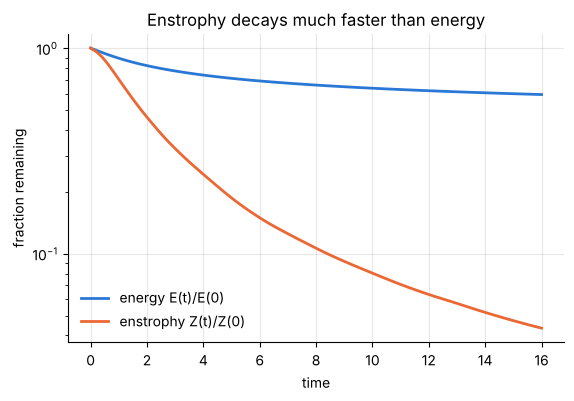

In [14]:
history = np.array([energy_enstrophy(field, g) for field in fields])
E, Z = history.T
energy_lost = E[0] - E[-1]
budget = 2 * nu_turb * np.trapezoid(Z, times)
print(f"energy:    {E[0]:.4f} -> {E[-1]:.4f}   ({100 * (1 - E[-1] / E[0]):.0f} % lost)")
print(f"enstrophy: {Z[0]:.3f} -> {Z[-1]:.3f}   ({100 * (1 - Z[-1] / Z[0]):.0f} % lost)")
print(f"energy lost {energy_lost:.5f}   2ν ∫ Z dt = {budget:.5f}")
assert np.all(np.diff(E) < 0) and np.all(np.diff(Z) < 0)
assert abs(budget / energy_lost - 1) < 2e-3                              # limited by the trapezoidal rule in time
assert Z[-1] / Z[0] < 0.1 and E[-1] / E[0] > 0.5

fig, ax = plt.subplots()
ax.semilogy(times, E / E[0], label="energy E(t)/E(0)")
ax.semilogy(times, Z / Z[0], label="enstrophy Z(t)/Z(0)")
ax.set(xlabel="time", ylabel="fraction remaining", title="Enstrophy decays much faster than energy")
ax.legend(frameon=False, loc="lower left");

The enstrophy falls by 96 per cent while the energy loses less than half. Enstrophy is carried
to small scales, where viscosity destroys it, while energy moves the other way, to large
scales, where viscosity is weak. This two-way traffic (the direct enstrophy cascade and the
**inverse energy cascade**) is the signature of two-dimensional turbulence. At this modest
Reynolds number the energy loss is still substantial. In separate runs from the same initial
field with half and a quarter of the viscosity (on $240^2$ and $320^2$ points, not included
here) the energy loss falls to 26 and 16 per cent, while the enstrophy loss stays near 90 per
cent (92 and 89).

**The energy spectrum.** $E(k)$ is the kinetic energy held by all modes with wavenumber
magnitude near $k$. In Fourier space the energy of a mode is $\tfrac12|\hat\omega|^2/k^2$.

fitted slope of E(k) for 4 <= k <= 20 at t = 16: -4.4
wavenumber holding the most energy: 6 at t = 0, 1 at t = 16


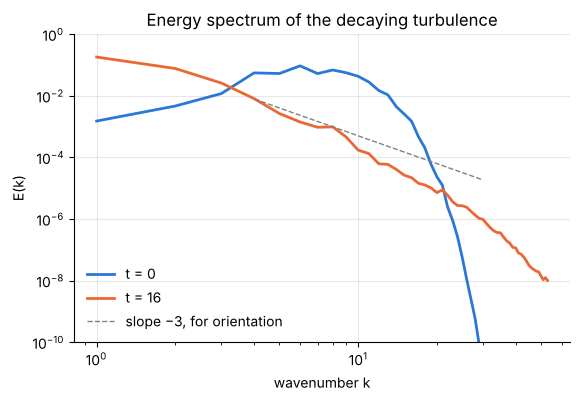

In [15]:
def energy_spectrum(omega):
    """Kinetic energy in shells of unit width in wavenumber magnitude: returns k = 1, 2, ... and E(k)."""
    N = len(omega)
    k1 = np.fft.fftfreq(N, 1 / N)
    k_magnitude = np.sqrt(k1[:, None] ** 2 + k1[None, :] ** 2)
    mode_energy = 0.5 * np.abs(fft2(omega) / N**2) ** 2 / np.maximum(k_magnitude, 1) ** 2
    mode_energy[0, 0] = 0.0
    shells = np.bincount(np.rint(k_magnitude).astype(int).ravel(), weights=mode_energy.ravel())
    return np.arange(1, N // 2), shells[1 : N // 2]

k_shell, E_start = energy_spectrum(fields[0])
_, E_end = energy_spectrum(fields[-1])
assert np.isclose(E_end.sum(), E[-1], rtol=1e-10)                         # Parseval: the shells add up to the energy

resolved = k_shell < g.N / 3                                                 # the modes kept by the 2/3 rule
inertial = (k_shell >= 4) & (k_shell <= 20)
slope = np.polyfit(np.log(k_shell[inertial]), np.log(E_end[inertial]), 1)[0]
print(f"fitted slope of E(k) for 4 <= k <= 20 at t = 16: {slope:.1f}")
print(f"wavenumber holding the most energy: {k_shell[np.argmax(E_start)]} at t = 0, {k_shell[np.argmax(E_end)]} at t = 16")
assert k_shell[np.argmax(E_end)] < k_shell[np.argmax(E_start)]

fig, ax = plt.subplots()
ax.loglog(k_shell[resolved], E_start[resolved], label="t = 0")
ax.loglog(k_shell[resolved], E_end[resolved], label="t = 16")
ax.loglog(k_shell[3:30], 0.5 * k_shell[3:30] ** -3.0, "--", color="0.5", lw=1, label="slope −3, for orientation")
ax.set(xlabel="wavenumber k", ylabel="E(k)", ylim=(1e-10, 1), title="Energy spectrum of the decaying turbulence")
ax.legend(frameon=False, loc="lower left");

The peak of the spectrum has moved from the wavenumber of the initial eddies to the largest
scales the box allows: the inverse cascade again.

The classical theory of Kraichnan and Batchelor predicts $E(k) \propto k^{-3}$ in the range of
the enstrophy cascade, for very large Reynolds number. This small simulation does not show
that law: its spectrum is steeper, as is usual in decaying simulations of this size, where a
few long-lived vortices dominate. Testing the theory takes forcing, grids in the thousands and
long averages. The program would be the same.

**Is it resolved?** The tail of the spectrum answers, as in notebooks 7 and 11. The strictest
form of the test looks at the enstrophy spectrum $k^2E(k)$, which weights the small scales, at
every saved time.

In [16]:
tail = []
for field in fields:
    _, E_k = energy_spectrum(field)
    Z_k = (k_shell**2 * E_k)[resolved]                                    # enstrophy spectrum
    tail.append(Z_k[-3:].mean() / Z_k.max())
tail = np.array(tail)
print(f"enstrophy spectrum at the cut-off, relative to its peak: worst {tail.max():.1e} at t = {times[np.argmax(tail)]:.1f},"
      f" and {tail[-1]:.1e} at t = {times[-1]:.0f}")
print(f"energy spectrum at t = {times[-1]:.0f}: {E_end[resolved][-1] / E_end.max():.1e} of its peak at the cut-off")
assert tail.max() < 0.05 and tail[-1] < 1e-3 and E_end[resolved][-1] < 1e-6 * E_end.max()

enstrophy spectrum at the cut-off, relative to its peak: worst 1.2e-02 at t = 1.2, and 9.7e-05 at t = 16
energy spectrum at t = 16: 5.6e-08 of its peak at the cut-off


At the end the run is comfortably resolved: the energy spectrum has fallen by seven decades
at the cut-off. The demanding moment is early, around $t = 1$, when the initial eddies are
strained into their thinnest filaments and about one per cent of the peak enstrophy density
sits at the cut-off. That is adequate for the pictures and for the budgets above, but not
for point values.

In fact no resolution would make the point values of this flow reproducible for long. The
evidence is from separate runs, not included here. A repeat on a grid of $240^2$ points from
the same initial field (interpolated) gives energy and enstrophy histories within 0.4 and 7
per cent of these, but its vorticity differs from the present one by a quarter of the peak
value at $t = 1$ and by more than half from $t = 4$ on: the vortices sit in different places.
The early difference is the marginal resolution just described. Refinement reduces it and
does not remove it: runs with $240^2$ and $320^2$ points still differ by 6 per cent of the
peak at $t = 2$ and by a third at $t = 6$, and at $240^2$ halving the time step from 0.008 to
0.004 still changes point values at $t = 16$ by 0.8 per cent of the peak. Turbulence is
chaotic: small differences of any origin grow until the fields are unrelated. Contrast this
with the shear layer of 15.7, where two grids agreed point by point. What a turbulence
simulation predicts is statistics, and those are what should be checked and reported.

## 15.9 Limits of this solver

- **Periodic boxes only.** A wall needs a Chebyshev grid in the wall-normal direction, and the
  stream function then satisfies a fourth-order equation with two conditions per wall, the
  clamped problem of notebook 14. Channel-flow codes are built in a similar way.
- **Three dimensions.** There is no scalar stream function, vortex lines are stretched, and
  the usual formulation works with the velocity and a projection onto divergence-free fields.
  Memory and time grow as $N^3$, and the range of scales grows with the Reynolds number. This
  is where spectral accuracy pays most: no other method gets as much from each grid point.
- **Smooth fields only.** Shocks, interfaces and sharp fronts bring back the Gibbs oscillations
  of notebook 3. Notebook 16 collects such cases.
- **Resolution is the user's responsibility.** The solver runs happily on a grid that is too
  coarse. Check the tail of the spectrum, and repeat with more points, as in 15.7.

## Summary

- In two dimensions the vorticity–stream function form removes the pressure and the
  incompressibility constraint. On a periodic domain the Poisson equation is a division by $k^2$.
- Pseudo-spectral means derivatives in Fourier space and products on the grid, at the cost of a
  few FFTs per step.
- Products alias. Keeping two thirds of the modes makes a quadratic term exact and restores the
  conservation of energy and enstrophy.
- An integrating factor removes the viscous stiffness, and RK4 handles the rest, with a time
  step set by advection.
- Verify with what is available: an exact solution, the order in time, invariants and budgets,
  and agreement between two resolutions.

## Exercises

1. **A diffusing vortex.** In an unbounded fluid the Gaussian (Lamb–Oseen) vortex
   $\omega = \dfrac{a_0^2}{a^2}\exp(-r^2/a^2)$ with $a^2 = a_0^2 + 4\nu t$ is an exact solution,
   where $r$ is the distance from its centre. Start the solver from this field with
   $a_0 = 0.3$, centred at $(\pi, \pi)$, with $\nu = 0.01$, $N = 64$ and $\Delta t = 0.01$, and
   compare with the formula at $t = 2$. The mean vorticity of this field is not zero, although
   15.1 says that it must be on a periodic domain. What does the solver do with the mean, and
   which flow does it therefore compute? How large is the error, and where does it come from?
2. **Growth rate of the Kelvin–Helmholtz instability.** Start from the two vorticity sheets of
   15.7 ($\delta = 0.15$, $\nu = 10^{-3}$, $N = 128$, $\Delta t = 0.02$) with the single
   disturbance $10^{-4}\cos 2x$ in place of the two used there. Save the field every 5 steps up
   to $t = 6$ and record the amplitude of the Fourier coefficient of the vertical velocity $v$
   with $(k_x, k_y) = (2, 0)$. Fit the exponential growth rate over $3 \le t \le 5$. (Before
   $t \approx 3$ the disturbance is still settling into the growing mode, and afterwards the rate
   keeps drifting because the layer thickens by diffusion, so the fit is an average.) Repeat for
   disturbances $\cos x$, $\cos 3x$ and $\cos 4x$ (same amplitude, reading the coefficient
   with the matching $k_x$). Which two grow fastest? For an inviscid layer of constant thickness
   $\delta$, linear theory (Michalke, 1964) gives the fastest growth at $k\delta \approx 0.44$
   with rate $0.19/\delta$. Compare, and explain the direction of the difference.
3. **Kolmogorov flow.** Add a steady body force to the vorticity equation by adding the term
   $F(x, y) = -n^3\nu\cos(ny)$ with $n = 4$ to the right-hand side (in `rhs`, as the Fourier
   transform of $F$). Show by hand that $\omega = -n\cos(ny)$, the flow $u = \sin(ny)$, is a
   steady solution. Start from that solution plus the disturbance $0.01\cos(x + 0.3)$ and run
   to $t = 100$ with $N = 64$, $\Delta t = 0.04$, for $\nu = 0.5$ and for $\nu = 0.05$. In which
   case does the flow return to the steady solution? Plot the final vorticity for both.
4. **Mixing a passive scalar.** A dye of concentration $c$ obeys
   $c_t + u\,c_x + v\,c_y = \kappa\nabla^2 c$. Extend the solver to advance $c$ together with
   $\omega$, with the same integrating-factor method. Use the shear layer of 15.7 at $N = 128$
   and $\Delta t = 0.016$, with $\kappa = 10^{-3}$ and $c(x, y, 0) = \cos y$. Compute the variance
   $\langle c^2\rangle$ up to $t = 14.4$ and compare it with pure diffusion, for which
   $\langle c^2\rangle = \tfrac12 e^{-2\kappa t}$. By what factor has the roll-up increased the
   loss of variance?
5. **Do two vortices merge?** Place two Gaussian vortices $10\exp(-r^2/a^2)$ with $a = 0.3$ at
   $(\pi \pm b/2, \pi)$ and run with $\nu = 10^{-3}$, $N = 128$, $\Delta t = 0.02$ up to
   $t = 20$, once with separation $b = 0.8$ and once with $b = 2$. Plot the vorticity at
   $t = 0, 5, 10, 15, 20$ for each case. In which case do the two vortices merge into one?
   Make the answer quantitative with the ratio of the vorticity at the midpoint $(\pi, \pi)$
   to the largest vorticity in the field, as a function of time.